In [28]:
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import numpy as np
import math
import json
import time
import subprocess

# First create the x and y coordinates of the points.
n_angles = 20
n_radii = 20
min_radius = 0.8
max_radius = 0.01
offsetx = 1.0
offsety = 0.0

radii = np.linspace(min_radius, max_radius, n_radii)

angles = np.linspace(0, 2 * np.pi, n_angles, endpoint=False)
angles = np.repeat(angles[..., np.newaxis], n_radii, axis=1)
angles[:, 1::2] += np.pi / n_angles

x = (radii * np.cos(angles)).flatten() + offsetx
y = (radii * np.sin(angles)).flatten() + offsety

# Create the Triangulation; no triangles so Delaunay triangulation created.
triang = tri.Triangulation(x, y)

triangles = triang.get_masked_triangles()
ncells = triangles.shape[0]
xy = np.concatenate((x[:, None], y[:, None]), axis=1)

print(triangles.shape)


config = {}


rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    rate[i] = 1.0e7

bgk_stddev = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    bgk_stddev[i] = 1.0e5

bgk_mean_x = np.zeros(ncells, dtype=np.float64)
bgk_mean_y = np.zeros(ncells, dtype=np.float64)
bgk_mean_z = np.zeros(ncells, dtype=np.float64)

for i in range(ncells):
    bgk_mean_y[i] = -3.0e4

ionisation_rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    ionisation_rate[i] = 1.0e5

config["mesh"] = {
    "type": "rotated_triangle",
    "vertices": xy.tolist(),
    "triangles": triangles.tolist()
}

config["bgk_processes"] = [
    {
        "rate": rate.tolist(),
        "bgk_stddev": bgk_stddev.tolist(),
        "bgk_mean_x": bgk_mean_x.tolist(),
        "bgk_mean_y": bgk_mean_y.tolist(),
        "bgk_mean_z": bgk_mean_z.tolist()
    }
]

config["ionisation_processes"] = [
    {
        "rate": ionisation_rate.tolist()
    }
]


config["sources"] = [
    {
        "type": "point",
        "pos": [1.01, 0, 0],
        "vel_mean": [100, 100, 0],
        "vel_stddev": 1000,
        "n_particles": 100000,
        "intensity": 1.0e19
    }
]

config["boundary_conditions"] = [
    {
        "type": "specular"
    }
]

config["max_steps"] = 1000000
config["seed"] = 0

inputstring = json.dumps(config)

# write inputstring to file
with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

(778, 3)
Simulation took 10.225432872772217 seconds


{'grid_building_time': 0.003584936, 'num_collisions': 92100658, 'num_crossings': 44815535, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 100000, 'total_time': 10.192647088, 'trace_time': 10.189062152}


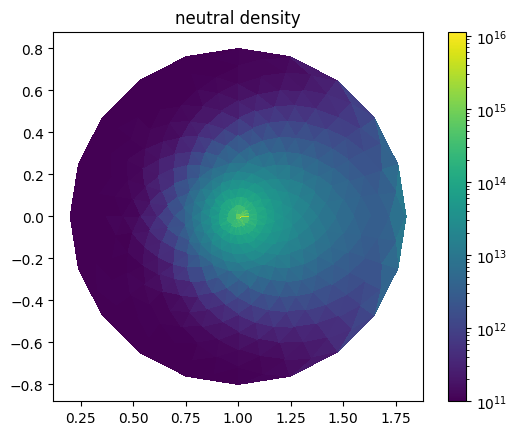

In [29]:


with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"])

fig1, ax1 = plt.subplots()
ax1.set_aspect('equal')
tpc = ax1.tripcolor(x, y, neutral_density + 1.0e11, triangles=triangles, shading='flat', norm="log")
fig1.colorbar(tpc)
ax1.set_title('neutral density')

plt.show()